In [1]:
import sys
import os
import time

import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.fft import fft
from scipy.signal import find_peaks
from scipy.stats import skew

sys.path.insert(0, '../../..') # Load Parent directory to import utils
from utils.constants import Configs

### Load Data From cache

In [ ]:
cache_path = Configs.SMART_RETAIL_FILTERED_DATA_BIMANUAL

if not os.path.exists(cache_path):
    raise FileNotFoundError(f"Processed data not found at {cache_path}. Please run the data processing notebook first.")
df = pd.read_csv(cache_path)

In [3]:
print(df.head())

   sub  repID  movID  movType  step movLabel        x_L         y_L  \
0    1      1      1        0     1     Pick   3.869636 -176.157427   
1    1      1      1        0     2     Pick  -0.544874 -178.506294   
2    1      1      1        0     3     Pick  -4.912739 -180.501706   
3    1      1      1        0     4     Pick  -9.227529 -182.200769   
4    1      1      1        0     5     Pick -13.482816 -183.660587   

          z_L        x_R  ...     vel_L     acc_L       k_L       t_L  \
0  867.144769  46.037028  ...  0.314419  0.368028  2.618244 -1.387820   
1  866.873175  46.163147  ...  0.310089  0.658925  4.893958 -1.732887   
2  866.697569  46.191874  ...  0.299228  1.044781  8.587954 -2.463496   
3  866.598030  46.153879  ...  0.286628  1.055988  9.614970 -3.797109   
4  866.554639  46.079830  ...  0.275769  0.841129  7.997407 -3.507823   

     jerk_L     vel_R     acc_R        k_R        t_R    jerk_R  
0  0.000000  0.025818  0.020991   5.036018   0.149055  0.000000  
1 

In [ ]:
def calculate_sparc(speed_profile, fs=60.0):
    """
    Calculates the SPARC (Spectral Arc Length) - The best metric to evaluate the "sinuosity" of speed
    - speed_profile: 1D array of the 'vel' column
    - fs: Sampling frequency in Hz (assumes 50Hz, change if your data is different)
    """
    if len(speed_profile) < 2: return 0
    # Normalization
    speed_profile = speed_profile / speed_profile.max()
    N = len(speed_profile)
    # FFT resolution 
    Nfft = int(2**(np.ceil(np.log2(N)) + 4))
    
    speed_spectrum = np.abs(fft(speed_profile, Nfft))
    freq = np.linspace(0, fs/2, Nfft//2)
    speed_spectrum = speed_spectrum[:Nfft//2] / speed_spectrum.max()
    
    # Corte a 10Hz (frequência limite para movimentos humanos normais)
    fc_idx = np.searchsorted(freq, 10.0)
    spectrum_cut = speed_spectrum[:fc_idx]
    
    # Calculate the arc length
    df = (freq[1] - freq[0])
    ds = np.sqrt(df**2 + np.diff(spectrum_cut)**2)
    return -np.sum(ds)

def calculate_ldlj(jerk_profile, duration_sec, distance):
    """
    Calculates LDLJ (Log Dimensionless Jerk) - metric for smoothness of movement
    - jerk_profile: 1D array of the 'jerk' column
    - duration_sec: duration of the movement in seconds
    - distance: distance traveled in meters
    """
    if distance <= 0 or duration_sec <= 0:
        return 0
    
    dt = duration_sec / len(jerk_profile)
    integral_jerk_sq = np.sum(jerk_profile**2) * dt
    
    dsj = (duration_sec**5 / distance**2) * integral_jerk_sq
    
    return -np.log(dsj) if dsj > 0 else 0

def count_zero_crossings(acc_profile, noise_threshold=0.01):
    """
    Remove small noises around 0 to count real changes in acceleration to deceleration.
    """
    # Only consider that the acceleration changed sign if it passes a minimum threshold (e.g., 0.01 m/s^2)
    acc_clean = np.where(np.abs(acc_profile) > noise_threshold, acc_profile, 0)
    # Search where the signal passes from positive to negative (and vice-versa), ignoring the zeros in between
    acc_clean = acc_clean[acc_clean != 0] 
    if len(acc_clean) < 2:
        return 0
    return len(np.where(np.diff(np.sign(acc_clean)))[0])

In [5]:
def arm_features(group, s, dt, fs):
    """s = 'L' or 'R'. Assumed columns: x_s, y_s, z_s, vel_s, acc_s, jerk_s, k_s, t_s."""
    xyz = group[[f'x_{s}', f'y_{s}', f'z_{s}']].values
    vel = group[f'vel_{s}'].values
    acc = group[f'acc_{s}'].values
    jerk = group[f'jerk_{s}'].values
    duration_sec = len(group) * dt

    straight = np.linalg.norm(xyz[-1] - xyz[0])
    path_length = np.sum(np.linalg.norm(np.diff(xyz, axis=0), axis=1))
    max_vel = vel.max()

    peaks, _ = find_peaks(vel, prominence=max_vel * 0.10)
    f = {
        'range_x': np.ptp(xyz[:, 0]), 'range_y': np.ptp(xyz[:, 1]), 'range_z': np.ptp(xyz[:, 2]),
        'path_length': path_length,
        'path_ratio': path_length / straight if straight > 0 else 1.0,
        'mean_vel': vel.mean(), 'max_vel': max_vel,
        'time_to_peak_vel': np.argmax(vel) * dt,
        'mean_to_peak_vel_ratio': vel.mean() / max_vel if max_vel > 0 else 0,
        'vel_skewness': skew(vel),
        'n_velocity_peaks': len(peaks),
        'mean_acc': acc.mean(), 'max_acc': acc.max(),
        'max_jerk': np.abs(jerk).max(),
        'ldlj': calculate_ldlj(jerk, duration_sec, path_length),
        'sparc': calculate_sparc(vel, fs),
        'total_curvature': group[f'k_{s}'].sum(),
        'total_torsion': group[f't_{s}'].sum(),
    }
    return {f'{k}_{s}': v for k, v in f.items()}

def coordination_features(group, dt):
    pL = group[['x_L', 'y_L', 'z_L']].values
    pR = group[['x_R', 'y_R', 'z_R']].values
    d = np.linalg.norm(pR - pL, axis=1)            # inter-wrist distance
    vL, vR = group['vel_L'].values, group['vel_R'].values

    corr = np.corrcoef(vL, vR)[0, 1] if vL.std() > 0 and vR.std() > 0 else 0.0
    return {
        'wrist_dist_mean': d.mean(), # mean inter-wrist distance
        'wrist_dist_min': d.min(), # minimum inter-wrist distance
        'wrist_dist_max': d.max(), # maximum inter-wrist distance
        'wrist_dist_std': d.std(), # standard deviation of inter-wrist distance
        'peak_time_diff': (np.argmax(vL) - np.argmax(vR)) * dt,   # L minus R
        'vel_corr_LR': corr, # pearson correlation coefficients between left and right wrist velocities
    }

### Do Feature Extraction for all movements and save them to cache

In [6]:
all_features = {}
times = []
fs = Configs.FS
dt = 1.0 / fs

for movement in ["Pick", "Move", "Park"]:
    print(f"Extracting features for movement: {movement}")
    start_time = time.perf_counter()

    cache_path = Configs.wrist_only_feature_extraction_features(movement)
    mov_data = df[df['movLabel'] == movement]
    groups = mov_data.groupby(['sub', 'repID', 'movID'])
    features_list = []

    for (sub, repID, movID), group in groups:
        # Garantir ordenação temporal
        group = group.sort_values(by='step')

        row = {'sub': sub, 'repID': repID, 'movID': movID, 'movLabel': movement,
               'duration': len(group) * dt}

        row.update(arm_features(group, 'L', dt, fs))
        row.update(arm_features(group, 'R', dt, fs))
        row.update(coordination_features(group, dt))
        features_list.append(row)
        
        features_df = pd.DataFrame(features_list)

    features_df = pd.DataFrame(features_list)
    all_features[movement] = features_df
    
    end_time = time.perf_counter()
    elapsed = end_time - start_time
    times.append(elapsed)

    # Export all features to cache
    print(f"Features extracted in {elapsed:.2f} seconds.")
    joblib.dump(features_df, cache_path)

Extracting features for movement: Pick
Features extracted in 2.23 seconds.
Extracting features for movement: Move
Features extracted in 0.00 seconds.
Extracting features for movement: Park
Features extracted in 0.92 seconds.


In [7]:
times

[2.2277435749999768, 0.0021483969999280816, 0.918834310999955]

In [8]:
all_features["Pick"]

,sub,repID,movID,movLabel,duration,range_x_L,range_y_L,range_z_L,path_length_L,path_ratio_L,...,ldlj_R,sparc_R,total_curvature_R,total_torsion_R,wrist_dist_mean,wrist_dist_min,wrist_dist_max,wrist_dist_std,peak_time_diff,vel_corr_LR
0,1,1,1,Pick,1.766667,97.768326,15.350249,4.982273,105.697157,1.091933,...,10.742022,-10.773168,6134.558329,-1476.238992,377.560392,349.787200,424.026403,16.349872,-1.583333,-0.497525
1,1,1,3,Pick,2.266667,460.891543,64.228583,235.759622,757.391825,2.091713,...,10.767518,-10.508075,7904.513187,-1758.083212,388.917642,302.784685,447.114641,38.024323,-0.016667,0.869998
2,1,1,5,Pick,3.183333,474.738720,151.181497,519.134762,1033.767013,1.810108,...,9.669601,-10.316078,10936.085524,-716.298829,452.087464,346.256361,736.343857,128.509846,-0.316667,0.369836
3,1,1,7,Pick,3.100000,550.736387,122.855086,707.607007,1410.413979,1.948241,...,9.839735,-10.364156,16193.868632,-11142.347690,441.523296,350.129154,525.325656,49.262546,-0.100000,0.737217
4,1,2,1,Pick,1.016667,98.269538,42.143758,13.254448,143.121969,1.830439,...,11.623815,-10.554230,3361.455950,2638.483342,349.750751,325.530601,380.049283,17.405744,0.466667,-0.328470
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
375,19,4,7,Pick,0.933333,271.374254,126.299860,17.208373,315.194267,1.069442,...,15.104804,-10.264513,2030.393004,-418.909708,431.065632,301.610856,521.045166,78.214311,0.050000,0.883486
376,19,5,1,Pick,0.850000,142.509622,131.395168,29.908044,214.262449,1.140250,...,13.894416,-10.253745,2627.639060,-1646.590644,357.722682,226.689604,463.204047,80.704616,-0.083333,0.685177
377,19,5,3,Pick,3.266667,145.485082,110.647706,23.236828,343.650324,2.001984,...,8.403231,-11.248869,7087.091523,-161.894831,366.181258,274.037536,453.508303,37.462831,2.400000,-0.258634
378,19,5,5,Pick,2.850000,196.813219,141.365469,28.539604,276.760381,1.222674,...,9.418425,-11.023982,8310.936392,-23.687648,461.107581,324.126678,502.858083,47.557317,-1.866667,0.111675


## Plot Correlation Matrix

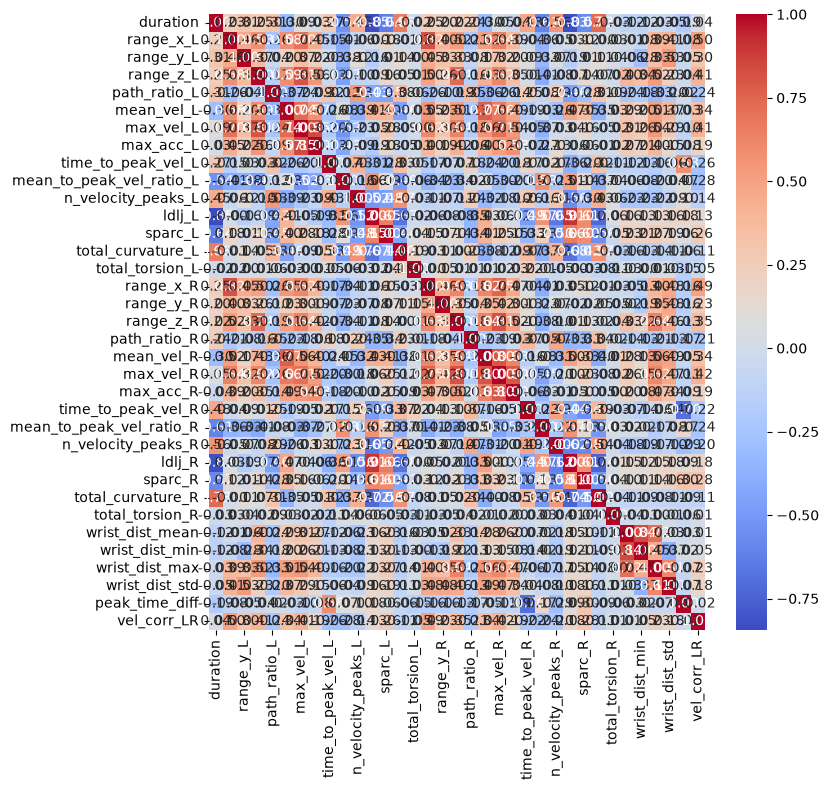

In [9]:
all_features_array = pd.concat(all_features.values(), ignore_index=True)
# MOVEMEN = "Pick" 

fig, ax = plt.subplots(figsize=(8, 8))
sns.heatmap(all_features_array[Configs.FEATURE_EXTRACTION_COLS_TO_TRAIN].corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=ax)
plt.show()

Foi utilizado o filtro de correlação de Pearson para fazer a seleção das features

In [10]:
X = all_features_array.drop(columns=['sub', 'repID', 'movID', 'movLabel'])
corr_matrix = X.corr().abs()

# Find exact pairs of highly correlated features
highly_correlated_pairs = []
threshold = 0.85

for i in range(len(corr_matrix.columns)):
    for j in range(i):
        if corr_matrix.iloc[i, j] > threshold:
            feature_1 = corr_matrix.columns[i]
            feature_2 = corr_matrix.columns[j]
            correlation_val = corr_matrix.iloc[i, j]
            highly_correlated_pairs.append((feature_1, feature_2, correlation_val))

In [11]:
FEATURE_COLS = [c for c in all_features_array.columns if c not in Configs.META_COLS] # To manually put in constants.py
print(len(FEATURE_COLS), FEATURE_COLS)

43 ['duration', 'range_x_L', 'range_y_L', 'range_z_L', 'path_length_L', 'path_ratio_L', 'mean_vel_L', 'max_vel_L', 'time_to_peak_vel_L', 'mean_to_peak_vel_ratio_L', 'vel_skewness_L', 'n_velocity_peaks_L', 'mean_acc_L', 'max_acc_L', 'max_jerk_L', 'ldlj_L', 'sparc_L', 'total_curvature_L', 'total_torsion_L', 'range_x_R', 'range_y_R', 'range_z_R', 'path_length_R', 'path_ratio_R', 'mean_vel_R', 'max_vel_R', 'time_to_peak_vel_R', 'mean_to_peak_vel_ratio_R', 'vel_skewness_R', 'n_velocity_peaks_R', 'mean_acc_R', 'max_acc_R', 'max_jerk_R', 'ldlj_R', 'sparc_R', 'total_curvature_R', 'total_torsion_R', 'wrist_dist_mean', 'wrist_dist_min', 'wrist_dist_max', 'wrist_dist_std', 'peak_time_diff', 'vel_corr_LR']
